# PEEK FIRST

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import os

figures_folder = r"E:\ADS2002_Melanoma\results\figures"

os.makedirs(figures_folder, exist_ok=True)

train_file = r"E:\ADS2002_Melanoma\data\splits\train.csv"
val_file = r"E:\ADS2002_Melanoma\data\splits\validation.csv"
test_file = r"E:\ADS2002_Melanoma\data\splits\test.csv"

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Training images: 23098
Validation images: 4657
Test images: 4946


In [2]:
print("Training dataset shape:")
print(train_df.shape)

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nFirst 5 rows:")
display(train_df.head())

Training dataset shape:
(23098, 9)

Missing values:
image_name                         0
patient_id                         0
lesion_id                          0
sex                               17
age_approx                        17
anatom_site_general_challenge    399
diagnosis                          0
benign_malignant                   0
target                             0
dtype: int64

First 5 rows:


,image_name,patient_id,lesion_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,IL_7972535,male,45.0,head/neck,unknown,benign,0
1,ISIC_0052212,IP_2842074,IL_9087444,female,50.0,lower extremity,nevus,benign,0
2,ISIC_0068279,IP_6890425,IL_4255399,female,45.0,head/neck,unknown,benign,0
3,ISIC_0074268,IP_8723313,IL_6898037,female,55.0,upper extremity,unknown,benign,0
4,ISIC_0074542,IP_4698288,IL_5017890,male,25.0,lower extremity,unknown,benign,0


benign_malignant
benign       22702
malignant      396
Name: count, dtype: int64


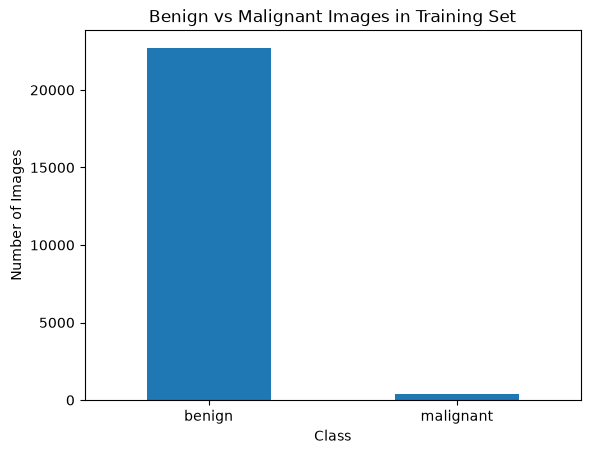

In [5]:
# Visualise the class imbalance
class_counts = train_df["benign_malignant"].value_counts()

print(class_counts)

class_counts.plot(kind="bar")

plt.title("Benign vs Malignant Images in Training Set")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.show()

sex
male      12156
female    10925
NaN          17
Name: count, dtype: int64


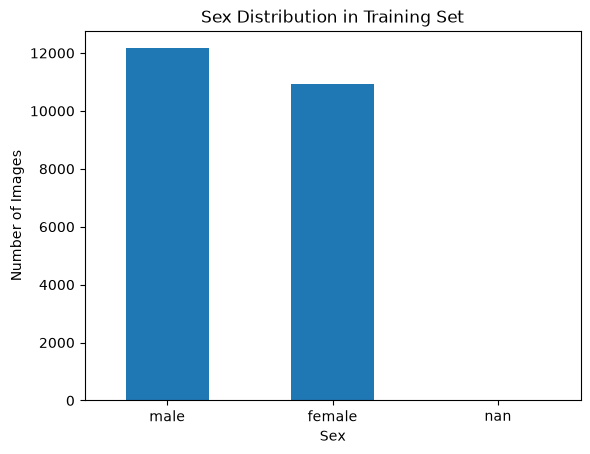

In [37]:
# Explore sex
sex_counts = train_df["sex"].value_counts(dropna=False)

print(sex_counts)

sex_counts.plot(kind="bar")

plt.title("Sex Distribution in Training Set")
plt.xlabel("Sex")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.savefig(
    figures_folder + r"\Sex Distribution in Training Set.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

count    23081.000000
mean        48.479485
std         14.657873
min          0.000000
25%         40.000000
50%         50.000000
75%         60.000000
max         90.000000
Name: age_approx, dtype: float64


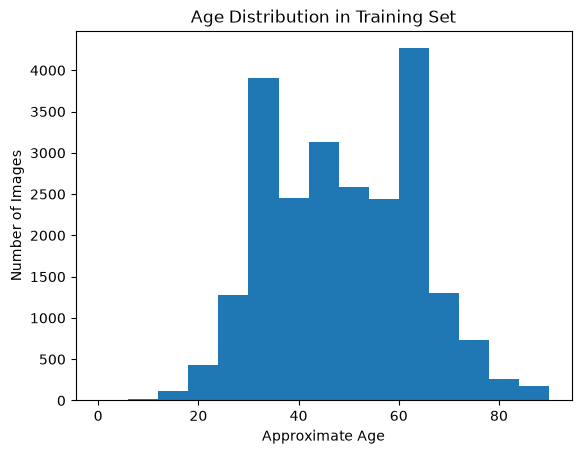

In [35]:
# Explore age
print(train_df["age_approx"].describe())

train_df["age_approx"].plot(
    kind="hist",
    bins=15
)

plt.title("Age Distribution in Training Set")
plt.xlabel("Approximate Age")
plt.ylabel("Number of Images")

plt.savefig(
    figures_folder + r"\Age Distribution in Training Set.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

anatom_site_general_challenge
torso              11727
lower extremity     5850
upper extremity     3475
head/neck           1280
NaN                  399
palms/soles          279
oral/genital          88
Name: count, dtype: int64


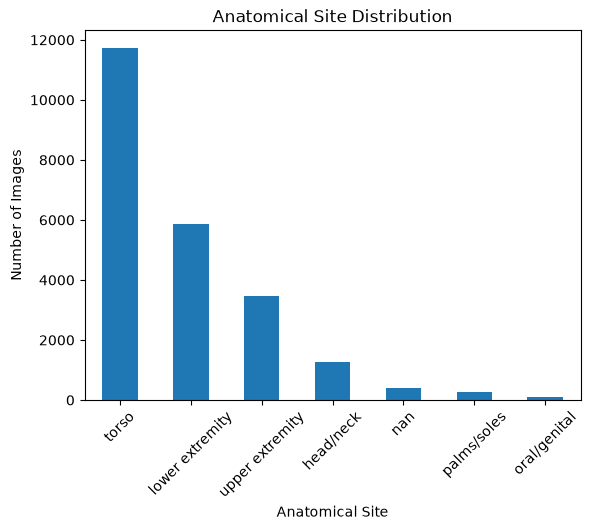

In [36]:
# Explore anatomical site
site_counts = train_df[
    "anatom_site_general_challenge"
].value_counts(dropna=False)

print(site_counts)

site_counts.plot(kind="bar")

plt.title("Anatomical Site Distribution")
plt.xlabel("Anatomical Site")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.savefig(
    figures_folder + r"\Anatomical Site Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# INITIALISE TEST

In [ ]:
# Compare melanoma rate by age
benign_ages = train_df[train_df['target'] == 0]['age_approx']
malignant_ages = train_df[train_df['target'] == 1]['age_approx']

In [17]:
print("Average age for benign images:")
print(benign_ages.mean())

print("\nAverage age for malignant images:")
print(malignant_ages.mean())

print("Median age for benign images:")
print(benign_ages.median())

print("\nMedian age for malignant images:")
print(malignant_ages.median())

Average age for benign images:
48.325765924619795

Average age for malignant images:
57.285353535353536
Median age for benign images:
50.0

Median age for malignant images:
60.0


In [21]:
# Compare melanoma rate by sex
female_df = train_df[train_df['sex'] == 'female']
female_melanoma_rate = female_df['target'].mean() * 100
print('Female melanoma rate:')
print(female_melanoma_rate)


male_df = train_df[train_df['sex'] == 'male']
male_melanoma_rate = male_df['target'].mean() * 100
print('\nMale melanoma rate:')
print(male_melanoma_rate)

Female melanoma rate:
1.3821510297482837

Male melanoma rate:
2.0154656136887135


In [27]:
# Compare melanoma rate by anatomical site
site_melanoma_rate = train_df.groupby('anatom_site_general_challenge')['target'].mean() * 100
print(site_melanoma_rate)

anatom_site_general_challenge
head/neck          4.296875
lower extremity    1.401709
oral/genital       4.545455
palms/soles        1.433692
torso              1.509337
upper extremity    1.956835
Name: target, dtype: float64


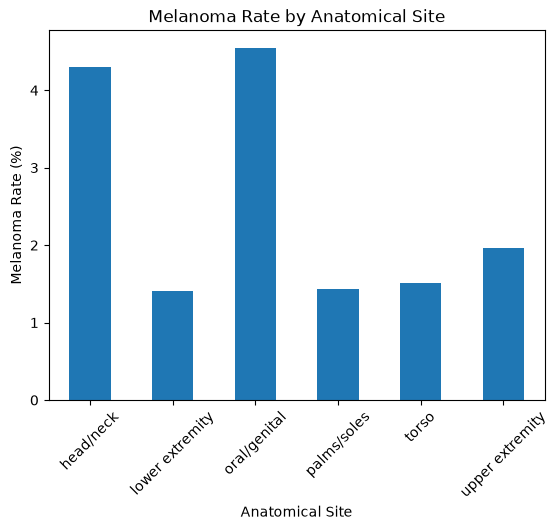

In [ ]:
site_melanoma_rate.plot(kind="bar")

plt.title("Melanoma Rate by Anatomical Site")
plt.xlabel("Anatomical Site")
plt.ylabel("Melanoma Rate (%)")
plt.xticks(rotation=45)

plt.savefig(
    figures_folder + r"\site_melanoma_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()